# Softmax: the course math and a checked NumPy implementation ? Step 8

Derive the model/loss/gradient, match the installed library penalty convention, and verify the optional NumPy implementation. Use development-train and validation only, without changing the Step 7 candidates or tuning on validation.

Read the [full derivation](../reports/SOFTMAX_MATH.md), [Assignment 3, Q10?Q11](../Assigments/assignment_3_3.py), [Assignment 5, Q2](../Assigments/assignment_5.py), and [lecture Section 8.5 / Appendix C.3](../documents/COE379L_lecture_notes%20%281%29.pdf).

In [1]:
from pathlib import Path
import sys
import importlib.metadata
import numpy as np
import pandas as pd
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src/schema.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.softmax_experiment import run_experiment
print("Interpreter:", sys.executable)
print("Versions:", {name: importlib.metadata.version(name) for name in ["numpy", "scikit-learn", "threadpoolctl"]})
print("Numerical-check precision:", np.dtype(np.float64))


Interpreter: C:\Users\jettw\Documents\Fall2026\ML\EcoSystem\.venv\Scripts\python.exe
Versions: {'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'threadpoolctl': '3.8.0'}
Numerical-check precision: float64


## Model and objective
Rows of $X$ are samples: $X\in\mathbb{R}^{1600\times27}$, $W\in\mathbb{R}^{27\times3}$, and $b\in\mathbb{R}^{3}$. Columns correspond to healthy, moderate stress, high stress.

$$Z=XW+\mathbf{1}b^T,\qquad P_{ik}=\frac{e^{Z_{ik}}}{\sum_j e^{Z_{ij}}}.$$

$$J(W,b)=-\frac1n\sum_i\log P_{i,y_i}+\frac{\lambda}{2}\|W\|_F^2.$$

Compute log-softmax after subtracting the row maximum. Use log probabilities directly for loss, so underflow of very small returned probabilities does not create infinite cross-entropy. The intercept is unpenalized; both labels and record IDs stay out of X.

## Derivative and the assignment connection
For one-hot Y, $\partial \log P_{ik}/\partial Z_{ij}=\delta_{kj}-P_{ij}$, so $\partial\ell_i/\partial Z_{ij}=P_{ij}-Y_{ij}$.

$$\nabla_WJ=\frac{X^T(P-Y)}{n}+\lambda W,\qquad \nabla_bJ=\operatorname{mean}_{i}(P_i-Y_i).$$

The binary summed gradient in Assignment 3 Q10 becomes a matrix of averaged class residuals, plus regularization. Full-batch GD subtracts a step times these gradients. Positive regularization controls weight growth on separable data (Q11). The actual project errors do not prove linear separability.

A common shift to all class logits preserves probabilities. The L2 penalty changes under common weight shifts, while a common intercept shift remains unpenalized. Compare probabilities/objectives, rather than expecting identical coefficients; changing to a reference-class penalty without adjusting it can change the regularized model.

## Library scaling and verification protocol
The installed scikit-learn L-BFGS source uses $\lambda=1/(Cn)$ for this unweighted mean-loss convention, hence $\lambda=0.000625$ for C=1 and n=1600. This is verified against the local implementation and recorded with its version/source hash.

The reference uses the same C/L2 model and transformed inputs with tighter optimizer tolerance for numerical verification only. NumPy uses zero initialization and full-batch GD with a training-design initial step and training-only Armijo backtracking. Validation controls neither step sizes nor stopping. Gradient checks use a tiny seeded float64 example and central finite differences.

In [2]:
math_result = run_experiment()
print("Finite-difference check:", math_result["gradient_check"])
print("Extreme logits:", math_result["extreme_logit_check"])
print("Simple synthetic problem:", math_result["synthetic_learning"])
print("Matched regularization:", math_result["regularization"])
print("NumPy optimizer:", math_result["numpy_optimizer"])
print("Library reference:", math_result["reference_optimizer"])
print("Probability/objective comparison:", math_result["comparison"])
display(pd.DataFrame([
    {"implementation": name, **{key: math_result[name][key] for key in ["accuracy", "macro_f1", "log_loss"]}}
    for name in ["validation_numpy", "validation_reference"]
]))


Finite-difference check: {'seed': 42, 'dtype': 'float64', 'step': 1e-05, 'parameters_checked': 15, 'max_absolute_error': 1.945163474736944e-11, 'relative_l2_error': 4.3204969074091856e-11}
Extreme logits: {'finite_log_probabilities': True, 'probability_sums_one': True, 'wrong_class_loss': 2000.0}
Simple synthetic problem: {'rows': 90, 'accuracy': 1.0, 'initial_objective': 1.0986122886681098, 'final_objective': 0.023464548031576226, 'iterations': 120, 'converged': True}
Matched regularization: {'C': 1.0, 'lambda': 0.000625, 'formula': '1/(C*n)', 'n': 1600, 'sklearn_version': '1.9.1', 'reference_solver': 'lbfgs', 'source_module': 'sklearn.linear_model._logistic._logistic_regression_path', 'source_sha256': '4ac9595c2fe4cf4612dea7f7cf3b6f0d2da68561bd3309ca9f273a33832dad7b'}
NumPy optimizer: {'method': 'full-batch gradient descent with training-only Armijo backtracking', 'initial_step': np.float64(1.299246217088928), 'max_iter': 20000, 'tolerance': 1e-08, 'iterations': 7031, 'converged': Tr

,implementation,accuracy,macro_f1,log_loss
0,validation_numpy,0.6025,0.534571,0.817637
1,validation_reference,0.6025,0.534571,0.817637


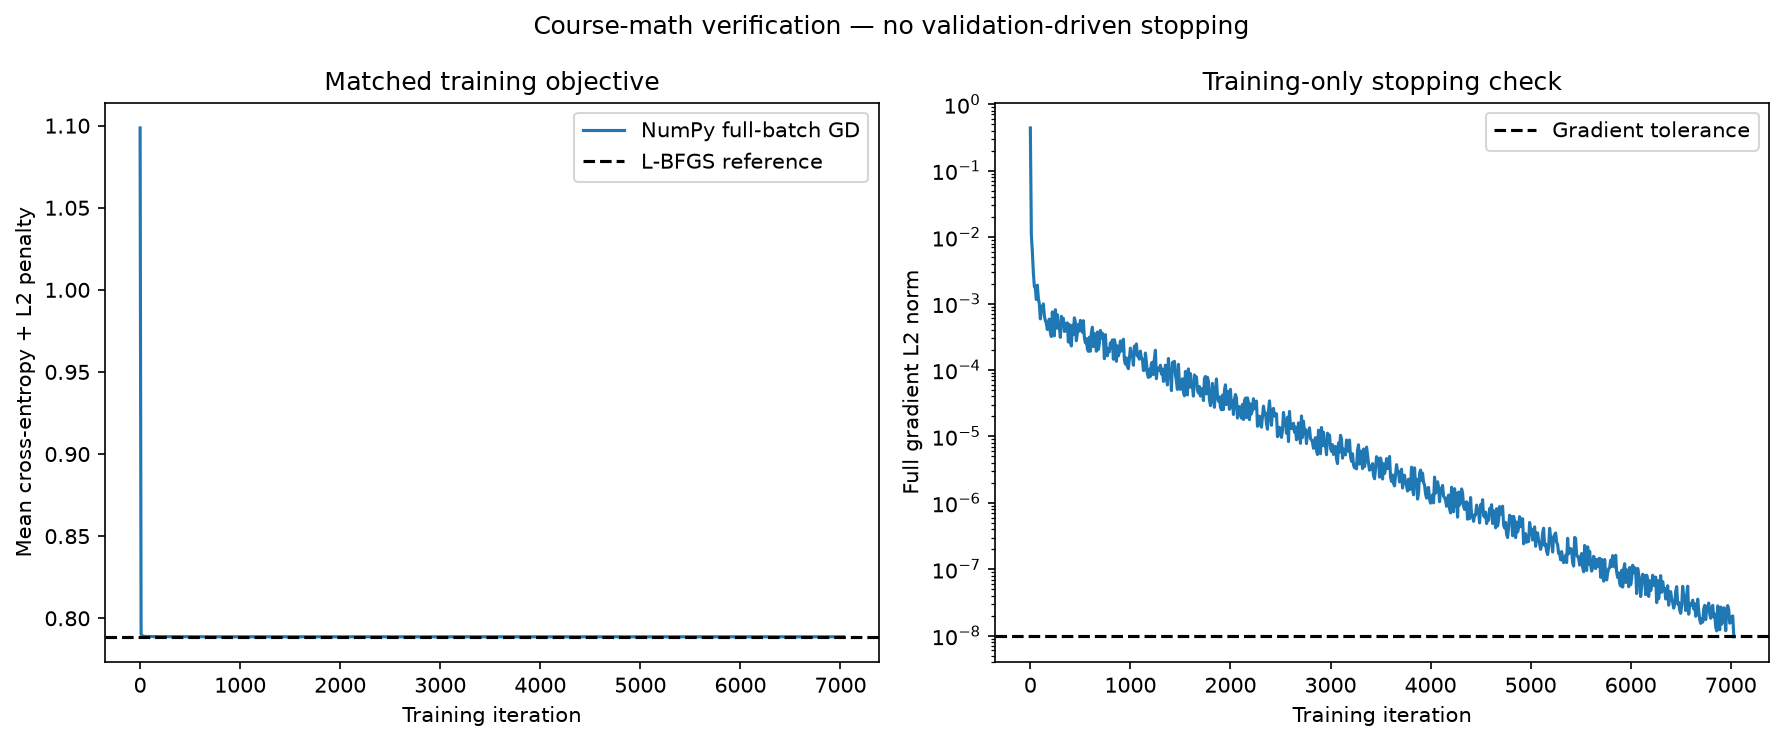

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "reports/figures/softmax_math_convergence.png")))


The training objective approaches the matched L-BFGS value and the full-gradient norm reaches its declared tolerance. Agreement verifies the numerical implementation; it does not select a stronger model or establish real-plant validity. The [summary](../reports/softmax_math_summary.json) records the measured errors and full optimizer history. No JAX installation was needed.

Step 7 candidate artifacts remain unchanged, and test data remains reserved. Next is Step 9: declare a small development-only search and select a model.